# Tugas 2: Metode Sains Komputasi (SK5001)

Nama: T. M. Aldine Al Kautsar

NIM: 20926005

## Soal 1: Dinamika Nonlinier dan Analisis Batas Keselamatan pada Bungee Jumping

Seorang penerjun lentur (*bungee jumper*) bermassa $m$ melompat dari jembatan setinggi $H$ di atas ngarai sungai. Gerak penerjun dipengaruhi oleh tiga gaya simultan: gaya gravitasi, hambatan udara (*Newtonian aerodynamic drag*), dan gaya pemulih tali lentur (*bungee cord*).

In [145]:
# Konstanta
h = 0.01
m = 80
g = 9.81
A = 0.1
L0 = 30
H = 80
k = 6.0

1. Gaya Hambatan Udara (Drag):

$$F_{friction}(v) = -0.65Av|v|$$

2. Gaya Pemulih Tali Pegas (Piecewise/Conditional Hooke’s Law):

$$F_{spring}(y) =\begin{cases}
    -k(y-L_0) & \text{jika } y > L_0 \\
    0   & \text{jika } y \le L_0
\end{cases}$$

In [146]:
import numpy as np

def friction(v):
  return -0.65*A*v*np.abs(v)

def spring(y):
  if y > L0:
    return -k*(y - L0)
  else:
    return 0

Persamaan differesial orde pertama:

$$\frac{dy}{dt} = v$$

$$\frac{dv}{dt} = g + \frac{F_{friction}(v)}{m} + \frac{F_{spring}(y)}{m}$$

In [147]:
def f(t, y):
  d = y[0]
  v = y[1]
  dydt = v
  dvdt = g + friction(v)/m + spring(d)/m
  return np.array([dydt, dvdt])

### 1. Implementasi Algoritma RK4 (*Runge-Kutta 4th Order*)
Fungsi integrasi RK4 mandiri dengan ukuran langkah waktu Δt = 0.01 s untuk menyelesaikan sistem persamaan diferensial di atas dengan nilai acuan 𝑘 = 6.0 N/m.

RK4 (*Runge-Kutta 4th Order*):

$$k_1 = f(t_n, y_n)$$

$$k_2 = f(t_n + \frac{h}{2}, y_n + h\frac{k_1}{2})$$

$$k_3 = f(t_n + \frac{h}{2}, y_n + h\frac{k_2}{2})$$

$$k_4 = f(t_n + h, y_n + hk_3)$$

In [148]:
def RK4(t, y):
  k1 = f(t, y)
  k2 = f(t + h/2, y + (h*k1/2))
  k3 = f(t + h/2, y + (h*k2/2))
  k4 = f(t + h, y + h*k3)
  return (1/6)*h*(k1+2*k2+2*k3+k4)

Simulasikan menggunakan:

$$y_{n} = y_{n-1} + \frac{1}{6}h(k_1+k_2+k_3+k_4)$$

$$t_n = t_{n-1} + h$$

In [149]:
t = 0
y = np.array([0,0])
sol = [[], [], []]
d = y[0]
v = y[1]

while(t < 60):
  y = RK4(t, np.array([d, v]))
  d += y[0]
  v += y[1]
  t += h
  sol[0].append(t)
  sol[1].append(d)
  sol[2].append(v)

### 2. Visualisasi Dinamika Sistem

#### a. Plot 1 (Profil Waktu)
Kurva posisi $y(t)$ dan kecepatan $v(t)$ terhadap waktu dalam satu jendela grafik

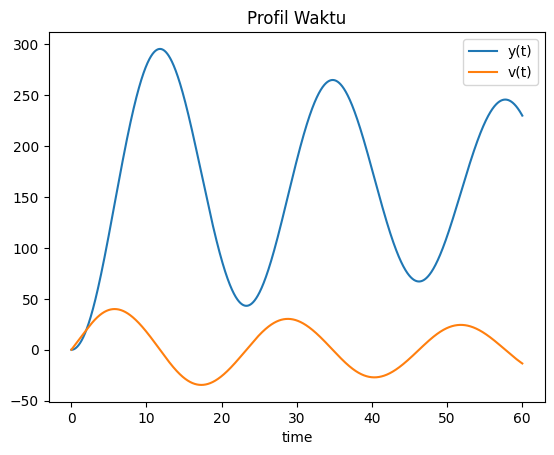

In [150]:
import matplotlib.pyplot as plt

plt.plot(sol[0], sol[1], label='y(t)')
plt.plot(sol[0], sol[2], label='v(t)')
plt.title('Profil Waktu')
plt.xlabel('time')
plt.legend()
plt.show()

#### b. Plot 2 (Ruang Fasa)
Diagram fasa kecepatan terhadap posisi $(y(t), v(t))$.

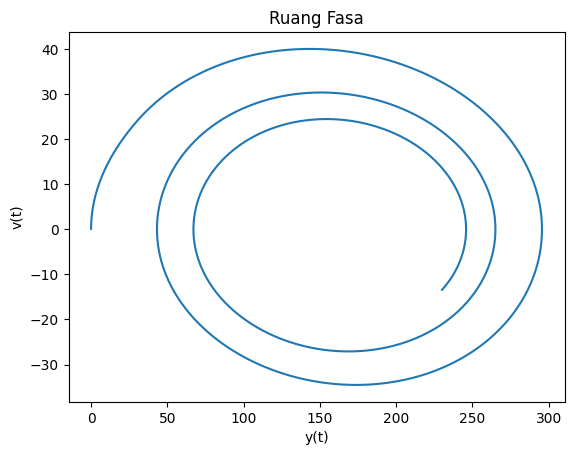

In [151]:
plt.plot(sol[1], sol[2])
plt.title('Ruang Fasa')
plt.xlabel('y(t)')
plt.ylabel('v(t)')
plt.show()

#### c. Plot 3 (Beban Percepatan Fisiologis)
Grafik *apparent weight / g-force total* yang dialami penerjun sebagai fungsi waktu, didefinisikan sebagai:

$$G(t) = \frac{|F_{spring}(y) + F_{friction}(v)|}{mg}$$

In [152]:
def G(t, y, v):
  return np.abs(spring(y) + friction(v)) / (m*g)

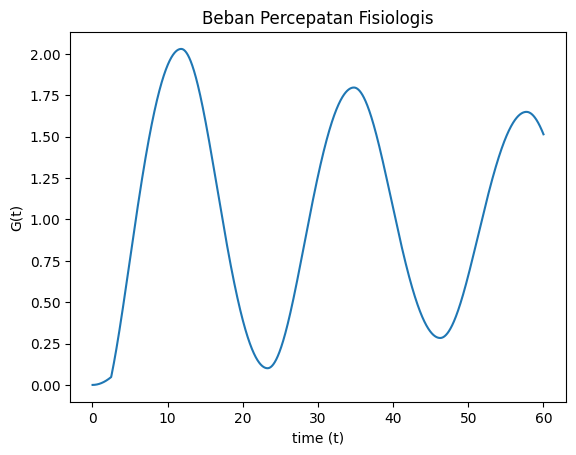

In [153]:
fisio = []

for i in range(len(sol[0])):
  fisio.append(G(sol[0][i], sol[1][i], sol[2][i]))

plt.plot(sol[0], fisio)
plt.title('Beban Percepatan Fisiologis')
plt.xlabel('time (t)')
plt.ylabel('G(t)')
plt.show()

### 3. Analisis Optimasi Parameter Keselamatan (Safety Optimization):

#### a. *Bisection method* untuk menentukan nilai minimum konstanta pegas $k_{min}$ di atas dasar ngarai $(y_{max} \le 75 m)$

Mendefinisikan fungsi agar dapat men-iterasi simulasi menggunakan input $k$ untuk output $y_{max}$

In [154]:
def k_to_max_y(k_bisec):

  k = k_bisec

  # Simulasi
  def spring(y, k):
    if y > L0:
      return -k*(y - L0)
    else:
      return 0
  def f(t, y):
    d = y[0]
    v = y[1]
    dydt = v
    dvdt = g + friction(v)/m + spring(d, k)/m
    return np.array([dydt, dvdt])
  def RK4(t, y):
    k1 = f(t, y)
    k2 = f(t + h/2, y + (h*k1/2))
    k3 = f(t + h/2, y + (h*k2/2))
    k4 = f(t + h, y + h*k3)
    return (1/6)*h*(k1+2*k2+2*k3+k4)
  t = 0
  y = np.array([0,0])
  sol = []
  d = y[0]
  v = y[1]
  while(t < 60):
    y = RK4(t, np.array([d, v]))
    d += y[0]
    v += y[1]
    t += h
    sol.append(d)

  return max(sol)

Menentukan *initial guess* $k_2$:

$k = 100$

In [155]:
y_k2 = k_to_max_y(100)
print(y_k2)

60.26358752369528


$y_{max}(k_2 = 100) \approx 60 \hspace{5mm} < \hspace{5mm}  y_{max}(k_x)= 75 \hspace{5mm} < \hspace{5mm} y_{max}(k_1 = 6) \approx 295$

Metode *Bisection* menggunakan *initial guess*:

$k_1 = 6 \\ k_2 = 100$

In [156]:
k1 = 6
k2 = 100

for i in range(0, 20):
  k_mid = k1 + ((k2 - k1) / 2)
  k_to_max_y(k_mid)
  if k_to_max_y(k_mid) > 75:
    k1 = k_mid
  else:
    k2 = k_mid
  error = np.abs(75-k_to_max_y(k_mid))
  print(f"k={k_mid:.2f}, y_max={k_to_max_y(k_mid):.2f}, error={error:.2f}")

k=53.00, y_max=76.84, error=1.84
k=76.50, y_max=66.25, error=8.75
k=64.75, y_max=70.67, error=4.33
k=58.88, y_max=73.48, error=1.52
k=55.94, y_max=75.08, error=0.08
k=57.41, y_max=74.26, error=0.74
k=56.67, y_max=74.66, error=0.34
k=56.30, y_max=74.87, error=0.13
k=56.12, y_max=74.97, error=0.03
k=56.03, y_max=75.02, error=0.02
k=56.08, y_max=75.00, error=0.00
k=56.05, y_max=75.01, error=0.01
k=56.06, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00
k=56.07, y_max=75.00, error=0.00


Konstanta pegas minimum untuk mendapatkan $y_{max} = 75 m$ adalah $k = 56.07 N/m$

#### b. Periksa apakah nilai $k_{min}$ tersebut batas $G_{max} \le 3.5$ tetap terpenuhi.

In [157]:
k = 56.07

t = 0
y = np.array([0,0])
sol = [[], [], []]
d = y[0]
v = y[1]

while(t < 60):
  y = RK4(t, np.array([d, v]))
  d += y[0]
  v += y[1]
  t += h
  sol[0].append(t)
  sol[1].append(d)
  sol[2].append(v)

fisio = []

for i in range(len(sol[0])):
  fisio.append(G(sol[0][i], sol[1][i], sol[2][i]))

print(f"k = {k}")
print(f"Max G = {max(fisio)}")

k = 56.07
Max G = 3.2151117401583527


Pada nilai $k = 56.07$, beban percepatan maksimum adalah $3.21$

### 4. Analisis Komputasi (Kekakuan & Diskontinuitas Gaya)

Bandingkan hasil simulasi RK4 dengan Metode Euler pada $\Delta t = 0.01$ dan $\Delta t = 0.1$

Metode RK4

In [158]:
rk = [[], [], []]
t = 0
d = 0
v = 0

while(t < 60):
  y = RK4(t, np.array([d, v]))
  d += y[0]
  v += y[1]
  t += h
  rk[0].append(t)
  rk[1].append(d)
  rk[2].append(v)

Metode Euler:
$$y_n = y_{n-1} + hf'(y_{n-1})$$

$$t_n = t_{n-1} + h$$

In [159]:
# dt = 0.1
eul01 = [[], [], []]
t = 0
d = 0
v = 0
h = 0.1
while(t < 60):
  y = [d, v]
  d += h*f(t, y)[0]
  v += h*f(t, y)[1]
  t += h
  eul01[0].append(t)
  eul01[1].append(d)
  eul01[2].append(v)


# dt = 0.01
eul001 = [[], [], []]
t = 0
d = 0
v = 0
h = 0.01
while(t < 60):
  y = [d, v]
  d += h*f(t, y)[0]
  v += h*f(t, y)[1]
  t += h
  eul001[0].append(t)
  eul001[1].append(d)
  eul001[2].append(v)

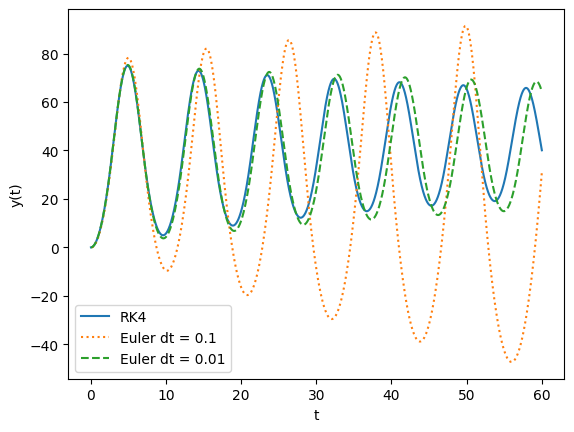

In [166]:
plt.plot(rk[0], rk[1], label='RK4')
plt.plot(eul01[0], eul01[1], label='Euler dt = 0.1', linestyle=':')
plt.plot(eul001[0], eul001[1], label='Euler dt = 0.01', linestyle='--')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.legend()
plt.show()

Terlihat bahwa pemilihan $\Delta t$ yang besar menyebabkan *artificial energy injection* pada $y=L_0$ karena perubahan $y(t)$ lebih kecil dari $\Delta t$. Maka dari itu, pemilihan $\Delta t$ yang kecil sangat penting.